In [15]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [16]:
!pip install medmnist

In [17]:
import numpy as np
import medmnist
from medmnist import INFO, BloodMNIST

print("medmnist version:", medmnist.__version__)

info = INFO["bloodmnist"]
for key in ["task", "n_channels", "n_samples", "license"]:
    print(key, ":", info.get(key))
print(info["label"])

train = BloodMNIST(split="train", download=True)
val = BloodMNIST(split="val", download=True)
test = BloodMNIST(split="test", download=True)

print()
print("train / val / test:", len(train), len(val), len(test))
print("images:", train.imgs.shape, train.imgs.dtype)
print("labels:", train.labels.shape)

medmnist version: 3.0.2
task : multi-class
n_channels : 3
n_samples : {'train': 11959, 'val': 1712, 'test': 3421}
license : CC BY 4.0
{'0': 'basophil', '1': 'eosinophil', '2': 'erythroblast', '3': 'immature granulocytes(myelocytes, metamyelocytes and promyelocytes)', '4': 'lymphocyte', '5': 'monocyte', '6': 'neutrophil', '7': 'platelet'}

train / val / test: 11959 1712 3421
images: (11959, 28, 28, 3) uint8
labels: (11959, 1)


In [18]:
# Cell 3: class counts
import pandas as pd

names = {int(k): v.split("(")[0].strip() for k, v in info["label"].items()}

rows = {}
for split_name, ds in [("train", train), ("val", val), ("test", test)]:
    rows[split_name] = pd.Series(ds.labels.ravel()).value_counts().sort_index()

counts = pd.DataFrame(rows).rename(index=names)
counts["train %"] = (counts["train"] / counts["train"].sum() * 100).round(1)
counts["test %"] = (counts["test"] / counts["test"].sum() * 100).round(1)
print(counts)
print()

majority = counts["train"].idxmax()
share = counts.loc[majority, "test"] / counts["test"].sum() * 100
print("most common class in train:", majority)
print("accuracy of always predicting it on test:", round(share, 1), "%")
print()
print("pixel min/max:", train.imgs.min(), train.imgs.max())
print("mean per colour channel (R, G, B):", train.imgs.mean(axis=(0, 1, 2)).round(1))

                       train  val  test  train %  test %
basophil                 852  122   244      7.1     7.1
eosinophil              2181  312   624     18.2    18.2
erythroblast            1085  155   311      9.1     9.1
immature granulocytes   2026  290   579     16.9    16.9
lymphocyte               849  122   243      7.1     7.1
monocyte                 993  143   284      8.3     8.3
neutrophil              2330  333   666     19.5    19.5
platelet                1643  235   470     13.7    13.7

most common class in train: neutrophil
accuracy of always predicting it on test: 19.5 %

pixel min/max: 0 255
mean per colour channel (R, G, B): [202.6 168.2 177.5]


cell 4 started


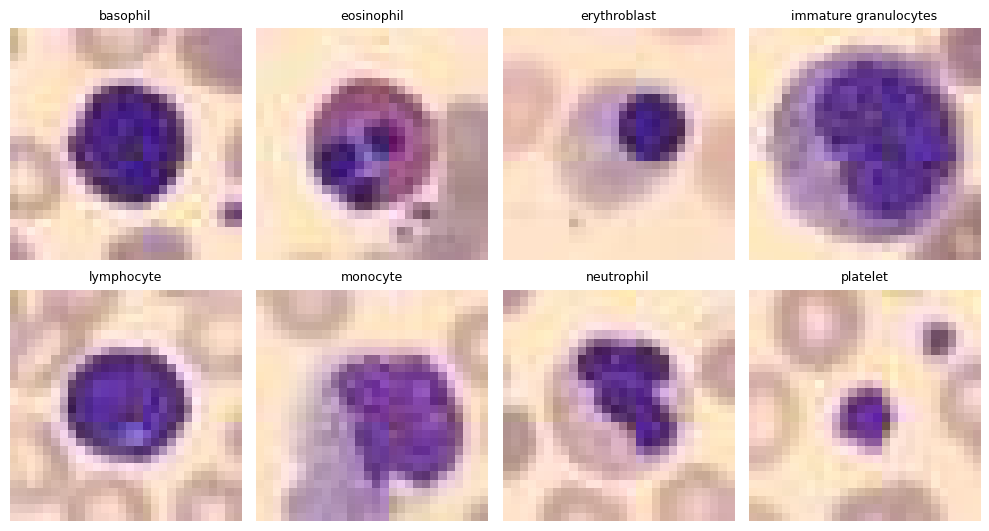

cell 4 finished


In [19]:

%matplotlib inline
import matplotlib.pyplot as plt
import os

os.makedirs("figures", exist_ok=True)
print("cell 4 started")

fig, axes = plt.subplots(2, 4, figsize=(10, 5.5))
for cls, ax in zip(range(8), axes.ravel()):
    idx = np.where(train.labels.ravel() == cls)[0][0]
    ax.imshow(train.imgs[idx])
    ax.set_title(names[cls], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig("figures/sample_images.png", dpi=150)
plt.show()

print("cell 4 finished")

In [20]:
# Cell 5: data prep and majority-class baseline, judged on the validation set
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import time

X_train = train.imgs.reshape(len(train), -1) / 255.0
y_train = train.labels.ravel()
X_val = val.imgs.reshape(len(val), -1) / 255.0
y_val = val.labels.ravel()
print("feature matrix:", X_train.shape)

def evaluate(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average="macro")
    print(f"{name}: accuracy = {acc:.3f}, macro-F1 = {f1:.3f}")

maj_class = np.bincount(y_train).argmax()
evaluate("majority class", y_val, np.full(len(y_val), maj_class))

feature matrix: (11959, 2352)
majority class: accuracy = 0.195, macro-F1 = 0.041


In [21]:
# Cell 5b: logistic regression on raw pixels (timed)
t0 = time.time()
logreg = LogisticRegression(max_iter=100)
logreg.fit(X_train, y_train)
print(f"fit took {time.time() - t0:.0f} seconds")
evaluate("logistic regression (pixels)", y_val, logreg.predict(X_val))

fit took 22 seconds
logistic regression (pixels): accuracy = 0.810, macro-F1 = 0.782


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [22]:
# Cell 5c: random forest on raw pixels (timed)
t0 = time.time()
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
print(f"fit took {time.time() - t0:.0f} seconds")
evaluate("random forest (pixels)", y_val, rf.predict(X_val))

fit took 32 seconds
random forest (pixels): accuracy = 0.849, macro-F1 = 0.824


In [23]:
# Cell 6: PyTorch and device
import torch
import torch.nn as nn
import torch.utils.data as data
import torchvision.transforms as transforms

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch version:", torch.__version__)
print("using device:", device)
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

torch version: 2.11.0+cu128
using device: cuda
GPU name: Tesla T4


In [24]:
# Cell 7: PyTorch datasets and loaders (no test loader on purpose)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

train_ds = BloodMNIST(split="train", transform=transform, download=True)
val_ds = BloodMNIST(split="val", transform=transform, download=True)

BATCH_SIZE = 128
train_loader = data.DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = data.DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)

xb, yb = next(iter(train_loader))
print("images batch:", xb.shape, xb.dtype)
print("labels batch:", yb.shape)
print("value range after normalisation:", round(xb.min().item(), 2), round(xb.max().item(), 2))
print("batches per epoch (train):", len(train_loader))

images batch: torch.Size([128, 3, 28, 28]) torch.float32
labels batch: torch.Size([128, 1])
value range after normalisation: -0.97 1.0
batches per epoch (train): 94


In [25]:
# Cell 8: a small CNN
class SmallCNN(nn.Module):
    def __init__(self, n_classes=8):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 28 -> 14
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 14 -> 7
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 7 -> 3
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 3 * 3, 64), nn.ReLU(),
            nn.Linear(64, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = SmallCNN().to(device)
print(model)
print("trainable parameters:", sum(p.numel() for p in model.parameters()))
with torch.no_grad():
    print("output shape for one batch:", model(xb.to(device)).shape)

SmallCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=576, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=8, bias=True)
  )
)
trainable parameters: 61032
output shape for one batch: torch.Size([128, 8])


In [26]:

# Cell 9: training, selecting the epoch by validation macro-F1
import copy, time
from sklearn.metrics import accuracy_score, f1_score

torch.manual_seed(42)
model = SmallCNN().to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
EPOCHS = 15

def run_epoch(loader, train):
    model.train(train)
    total_loss, n = 0.0, 0
    preds, labels = [], []
    for xb, yb in loader:
        xb = xb.to(device)
        yb = yb.squeeze(1).long().to(device)
        with torch.set_grad_enabled(train):
            logits = model(xb)
            loss = loss_fn(logits, yb)
        if train:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        total_loss += loss.item() * len(yb)
        n += len(yb)
        preds.append(logits.argmax(dim=1).cpu())
        labels.append(yb.cpu())
    preds = torch.cat(preds).numpy()
    labels = torch.cat(labels).numpy()
    return total_loss / n, accuracy_score(labels, preds), f1_score(labels, preds, average="macro")

history = []
best_f1, best_epoch, best_state = -1.0, 0, None
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc, tr_f1 = run_epoch(train_loader, train=True)
    va_loss, va_acc, va_f1 = run_epoch(val_loader, train=False)
    history.append(dict(epoch=epoch, tr_loss=tr_loss, tr_acc=tr_acc,
                        va_loss=va_loss, va_acc=va_acc, va_f1=va_f1))
    if va_f1 > best_f1:
        best_f1, best_epoch = va_f1, epoch
        best_state = copy.deepcopy(model.state_dict())
    print(f"epoch {epoch:2d} | train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
          f"val loss {va_loss:.3f} acc {va_acc:.3f} macro-F1 {va_f1:.3f} | {time.time() - t0:.0f}s")

model.load_state_dict(best_state)
print(f"\nbest epoch by validation macro-F1: {best_epoch} (macro-F1 = {best_f1:.3f})")

epoch  1 | train loss 1.329 acc 0.500 | val loss 0.905 acc 0.673 macro-F1 0.599 | 3s
epoch  2 | train loss 0.775 acc 0.719 | val loss 0.692 acc 0.745 macro-F1 0.690 | 3s
epoch  3 | train loss 0.624 acc 0.766 | val loss 0.562 acc 0.798 macro-F1 0.755 | 3s
epoch  4 | train loss 0.546 acc 0.800 | val loss 0.522 acc 0.809 macro-F1 0.775 | 3s
epoch  5 | train loss 0.468 acc 0.827 | val loss 0.436 acc 0.837 macro-F1 0.804 | 3s
epoch  6 | train loss 0.432 acc 0.842 | val loss 0.420 acc 0.848 macro-F1 0.817 | 3s
epoch  7 | train loss 0.410 acc 0.848 | val loss 0.408 acc 0.850 macro-F1 0.814 | 3s
epoch  8 | train loss 0.396 acc 0.855 | val loss 0.356 acc 0.879 macro-F1 0.858 | 3s
epoch  9 | train loss 0.360 acc 0.869 | val loss 0.346 acc 0.879 macro-F1 0.856 | 3s
epoch 10 | train loss 0.352 acc 0.871 | val loss 0.375 acc 0.866 macro-F1 0.840 | 3s
epoch 11 | train loss 0.327 acc 0.883 | val loss 0.373 acc 0.855 macro-F1 0.819 | 3s
epoch 12 | train loss 0.326 acc 0.881 | val loss 0.298 acc 0.893 

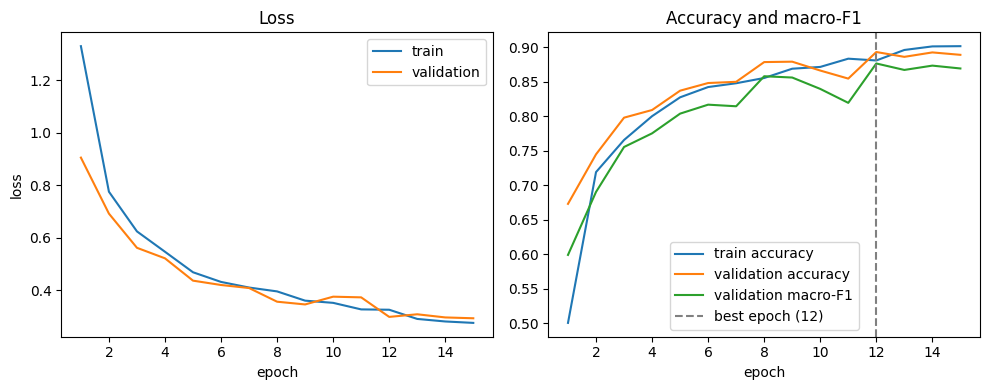

In [27]:
# Cell 10: training curves
import os
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)

hist = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(hist["epoch"], hist["tr_loss"], label="train")
axes[0].plot(hist["epoch"], hist["va_loss"], label="validation")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].set_title("Loss")
axes[0].legend()

axes[1].plot(hist["epoch"], hist["tr_acc"], label="train accuracy")
axes[1].plot(hist["epoch"], hist["va_acc"], label="validation accuracy")
axes[1].plot(hist["epoch"], hist["va_f1"], label="validation macro-F1")
axes[1].axvline(best_epoch, color="gray", linestyle="--", label=f"best epoch ({best_epoch})")
axes[1].set_xlabel("epoch")
axes[1].set_title("Accuracy and macro-F1")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/training_curves.png", dpi=150)
plt.show()

                       precision    recall  f1-score   support

             basophil      0.752     0.770     0.761       122
           eosinophil      0.977     0.968     0.973       312
         erythroblast      0.935     0.935     0.935       155
immature granulocytes      0.736     0.759     0.747       290
           lymphocyte      0.896     0.779     0.833       122
             monocyte      0.819     0.790     0.804       143
           neutrophil      0.945     0.976     0.960       333
             platelet      0.996     1.000     0.998       235

             accuracy                          0.893      1712
            macro avg      0.882     0.872     0.876      1712
         weighted avg      0.894     0.893     0.893      1712



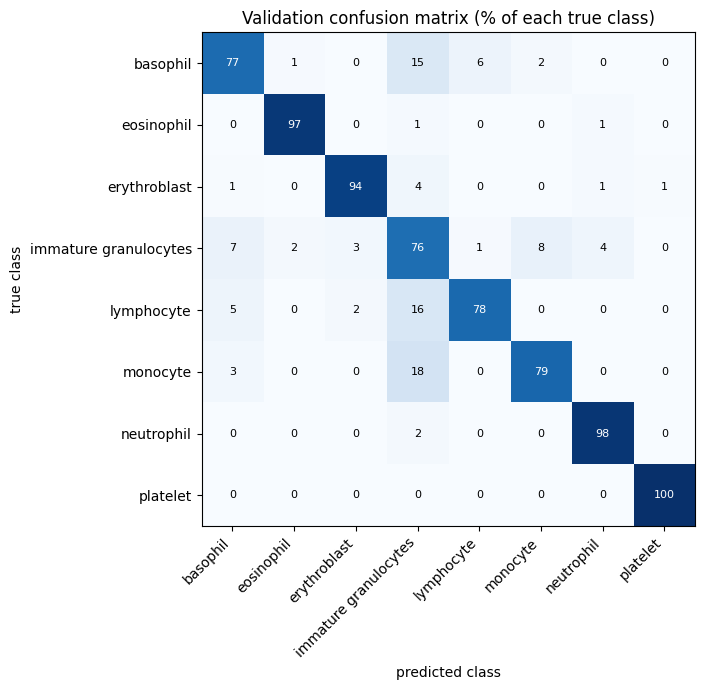

In [28]:
# Cell 11: validation confusion matrix with the best-epoch weights
from sklearn.metrics import confusion_matrix, classification_report

model.eval()
all_pred, all_true = [], []
with torch.no_grad():
    for xb_, yb_ in val_loader:
        out = model(xb_.to(device))
        all_pred.append(out.argmax(dim=1).cpu())
        all_true.append(yb_.squeeze(1).long())
y_pred = torch.cat(all_pred).numpy()
y_true = torch.cat(all_true).numpy()

labels = [names[i] for i in range(8)]
print(classification_report(y_true, y_pred, target_names=labels, digits=3))

cm = confusion_matrix(y_true, y_pred)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(8))
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticks(range(8))
ax.set_yticklabels(labels)
for i in range(8):
    for j in range(8):
        ax.text(j, i, f"{cm_pct[i, j]:.0f}", ha="center", va="center",
                color="white" if cm_pct[i, j] > 50 else "black", fontsize=8)
ax.set_xlabel("predicted class")
ax.set_ylabel("true class")
ax.set_title("Validation confusion matrix (% of each true class)")
plt.tight_layout()
plt.savefig("figures/confusion_matrix_val.png", dpi=150)
plt.show()

In [29]:
# Cell 12: same CNN, 5 different seeds, judged on validation only
import copy, time
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

def run_epoch_m(model, loader, optimizer=None):
    train_mode = optimizer is not None
    model.train(train_mode)
    preds, labels = [], []
    for xb, yb in loader:
        xb = xb.to(device)
        yb = yb.squeeze(1).long().to(device)
        with torch.set_grad_enabled(train_mode):
            logits = model(xb)
            loss = loss_fn(logits, yb)
        if train_mode:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        preds.append(logits.argmax(dim=1).cpu())
        labels.append(yb.cpu())
    preds = torch.cat(preds).numpy()
    labels = torch.cat(labels).numpy()
    return accuracy_score(labels, preds), f1_score(labels, preds, average="macro")

def train_one(seed, epochs=15, lr=1e-3):
    torch.manual_seed(seed)
    m = SmallCNN().to(device)
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    best = {"f1": -1.0}
    for ep in range(1, epochs + 1):
        run_epoch_m(m, train_loader, opt)
        acc, f1 = run_epoch_m(m, val_loader)
        if f1 > best["f1"]:
            best = {"f1": f1, "acc": acc, "epoch": ep}
    return best

results = []
for seed in [0, 1, 2, 3, 4]:
    t0 = time.time()
    best = train_one(seed)
    results.append({"seed": seed, "best_epoch": best["epoch"],
                    "val_acc": best["acc"], "val_macro_f1": best["f1"]})
    print(f"seed {seed}: best epoch {best['epoch']}, val acc {best['acc']:.3f}, "
          f"macro-F1 {best['f1']:.3f} ({time.time() - t0:.0f}s)")

seed_table = pd.DataFrame(results)
print()
print(seed_table.round(3).to_string(index=False))
print()
print("macro-F1: mean", round(seed_table["val_macro_f1"].mean(), 3),
      "| std", round(seed_table["val_macro_f1"].std(), 3),
      "| min", round(seed_table["val_macro_f1"].min(), 3),
      "| max", round(seed_table["val_macro_f1"].max(), 3))
print("accuracy: mean", round(seed_table["val_acc"].mean(), 3),
      "| std", round(seed_table["val_acc"].std(), 3))

seed 0: best epoch 15, val acc 0.895, macro-F1 0.877 (47s)
seed 1: best epoch 11, val acc 0.889, macro-F1 0.870 (47s)
seed 2: best epoch 14, val acc 0.885, macro-F1 0.870 (47s)
seed 3: best epoch 14, val acc 0.892, macro-F1 0.874 (47s)
seed 4: best epoch 14, val acc 0.883, macro-F1 0.858 (47s)

 seed  best_epoch  val_acc  val_macro_f1
    0          15    0.895         0.877
    1          11    0.889         0.870
    2          14    0.885         0.870
    3          14    0.892         0.874
    4          14    0.883         0.858

macro-F1: mean 0.87 | std 0.007 | min 0.858 | max 0.877
accuracy: mean 0.889 | std 0.005


In [30]:
# Cell 13: same CNN, 30 epochs instead of 15, same 5 seeds, validation only
results30 = []
for seed in [0, 1, 2, 3, 4]:
    t0 = time.time()
    best = train_one(seed, epochs=30)
    results30.append({"seed": seed, "best_epoch": best["epoch"],
                      "val_acc": best["acc"], "val_macro_f1": best["f1"]})
    print(f"seed {seed}: best epoch {best['epoch']}, val acc {best['acc']:.3f}, "
          f"macro-F1 {best['f1']:.3f} ({time.time() - t0:.0f}s)")

table30 = pd.DataFrame(results30)
compare = pd.DataFrame({
    "seed": seed_table["seed"],
    "15 epochs": seed_table["val_macro_f1"],
    "30 epochs": table30["val_macro_f1"],
})
compare["difference"] = compare["30 epochs"] - compare["15 epochs"]
print()
print(compare.round(3).to_string(index=False))
print()
print("mean macro-F1: 15 epochs", round(compare["15 epochs"].mean(), 3),
      "| 30 epochs", round(compare["30 epochs"].mean(), 3))
print("std:           15 epochs", round(compare["15 epochs"].std(), 3),
      "| 30 epochs", round(compare["30 epochs"].std(), 3))
print("mean difference:", round(compare["difference"].mean(), 3))
print("seeds where 30 epochs is better:", int((compare["difference"] > 0).sum()), "of 5")
print("best epochs (30-epoch runs):", table30["best_epoch"].tolist())

seed 0: best epoch 30, val acc 0.928, macro-F1 0.916 (94s)
seed 1: best epoch 26, val acc 0.918, macro-F1 0.907 (94s)
seed 2: best epoch 29, val acc 0.922, macro-F1 0.910 (93s)
seed 3: best epoch 29, val acc 0.922, macro-F1 0.910 (93s)
seed 4: best epoch 29, val acc 0.916, macro-F1 0.903 (94s)

 seed  15 epochs  30 epochs  difference
    0      0.877      0.916       0.040
    1      0.870      0.907       0.038
    2      0.870      0.910       0.040
    3      0.874      0.910       0.037
    4      0.858      0.903       0.046

mean macro-F1: 15 epochs 0.87 | 30 epochs 0.909
std:           15 epochs 0.007 | 30 epochs 0.005
mean difference: 0.04
seeds where 30 epochs is better: 5 of 5
best epochs (30-epoch runs): [30, 26, 29, 29, 29]


In [31]:
print("train_one" in globals(), "train_loader" in globals(), "val_loader" in globals(), "device" in globals())
if "device" in globals():
    print(device)

True True True True
cuda
